# Dự đoán xu hướng bài hát thịnh hành
* **Tệp dữ liệu đầu vào:** `data/processed/ml_tracks.csv` (39,190 bài hát độc nhất cấp Song-level).
* **Kết quả:** Hệ số mô hình, bảng đánh giá và biểu đồ được trình bày trong notebook. Notebook hiện không tự động xuất mô hình hoặc kết quả ra file.


## 1. KHỞI TẠO MÔI TRƯỜNG & THƯ VIỆN LÀM VIỆC


In [16]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)

warnings.simplefilter('default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

## 2. NẠP DỮ LIỆU & NGUYÊN TẮC CHỐNG RÒ RỈ DỮ LIỆU

### 2.1. Cấu trúc dữ liệu cấp Bài hát (Song-Level)
* Sử dụng tệp `data/processed/ml_tracks.csv` (39,190 bài hát độc nhất). Mỗi `track_id` xuất hiện đúng 1 dòng.
* Chia dữ liệu ở cấp bài hát giúp tránh cùng một `track_id` xuất hiện ở cả Train và Test như khi chia ngẫu nhiên các bản ghi xếp hạng theo tuần.
* Tập dữ liệu chỉ gồm những bài đã xuất hiện trên bảng xếp hạng; kết quả chưa đại diện cho toàn bộ bài hát được phát hành trên Spotify.

### 2.2. Phân loại biến Đầu vào ($X$) & Biến Mục tiêu ($y$)
**Biến mục tiêu:** `y = is_hit`, với `is_hit = 1` khi `pop_score >= 50`, còn lại là 0. Điểm `pop_score` tổng hợp thứ hạng, số tuần xuất hiện, độ phủ quốc gia và lượt nghe. Nhãn Hit là định nghĩa phục vụ nghiên cứu, không đồng nghĩa với việc lọt Top 50.

**Tập biến giải thích ($X$ - 10 đặc trưng âm học nội tại của bản thu):**
1. `danceability`: Độ phù hợp để khiêu vũ (0-1).
2. `energy`: Cường độ năng lượng của âm thanh (0-1).
3. `loudness`: Độ lớn âm thanh trung bình, tính bằng dB.
4. `speechiness`: Mức độ hiện diện của lời nói trong âm thanh (0-1).
5. `acousticness`: Chỉ số nhận diện âm thanh acoustic (0-1).
6. `instrumentalness`: Chỉ số nhận diện âm thanh không có giọng hát (0-1).
7. `liveness`: Chỉ số nhận diện sự hiện diện của khán giả trong bản thu (0-1).
8. `valence`: Mức độ tích cực của âm thanh (0-1), không phải phép đo trực tiếp cảm xúc người nghe.
9. `tempo`: Nhịp độ, tính bằng BPM.
10. `duration_min`: Thời lượng bài hát, tính bằng phút.

Các biến dùng tạo nhãn như `pop_score`, `peak_rank`, `nweek`, `total_streams` và `n_countries` không được đưa vào $X$. Đặc trưng âm học được giả định có thể xác định từ bản thu trước phát hành; phép chia ngẫu nhiên hiện tại chưa kiểm chứng khả năng dự báo các bài phát hành trong tương lai.


In [17]:
# 1. Nạp tập dữ liệu cấp bài hát
data_paths = [
    '../data/processed/ml_tracks.csv',
    'data/processed/ml_tracks.csv',
    'Spotify_Audio_Trends_Analytics/data/processed/ml_tracks.csv'
]
data_path = next((p for p in data_paths if os.path.exists(p)), None)
if not data_path:
    raise FileNotFoundError("Không tìm thấy tệp ml_tracks.csv trong các đường dẫn khả dụng!")

df = pd.read_csv(data_path)
print(f"Kích thước dữ liệu:{df.shape[0]:,} dòng × {df.shape[1]} cột")

# 2. Chuyển đổi thời lượng từ mili-giây sang phút
if 'duration_min' not in df.columns and 'duration' in df.columns:
    df['duration_min']=df['duration'] / 60000.0

# 3. Xác định 10 đặc trưng âm học đầu vào (X)
feature_cols = [
    'danceability', 'energy', 'loudness', 'speechiness', 
    'acousticness', 'instrumentalness', 'liveness', 'valence', 
    'tempo', 'duration_min'
]

# 4. Xác định biến mục tiêu (y: is_hit)
X=df[feature_cols]
y=df['is_hit']

# Kiểm tra giá trị khuyết thiếu
print("\nKiểm tra giá trị thiếu trong X:")
print(X.isnull().sum())

# Thống kê phân phối nhãn mục tiêu y
hit_counts=y.value_counts()
print("\nPhân phối nhãn mục tiêu:")
print(f"Nhóm 0 (Non-Hit): {hit_counts.get(0, 0):,} bài ({hit_counts.get(0, 0)/len(y)*100:.2f}%)")
print(f"Nhóm 1 (Hit): {hit_counts.get(1, 0):,} bài ({hit_counts.get(1, 0)/len(y)*100:.2f}%)")

display(X.describe())


Kích thước dữ liệu:39,190 dòng × 30 cột

Kiểm tra giá trị thiếu trong X:
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_min        0
dtype: int64

Phân phối nhãn mục tiêu:
Nhóm 0 (Non-Hit): 33,727 bài (86.06%)
Nhóm 1 (Hit): 5,463 bài (13.94%)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_min
count,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000
mean,0.6806,0.6328,-7.0259,0.1307,0.2770,0.0161,0.1739,0.5202,121.9775,3.3407
std,0.1417,0.1677,2.7380,0.1210,0.2509,0.0953,0.1322,0.2214,28.7928,0.9292
min,0.0859,0.0032,-41.4100,0.0223,0.0000,0.0000,0.0134,0.0000,31.2620,0.5022
25%,0.5900,0.5260,-8.3910,0.0428,0.0667,0.0000,0.0963,0.3480,98.0190,2.7905
50%,0.6970,0.6450,-6.6620,0.0759,0.1990,0.0000,0.1220,0.5200,120.0705,3.2253
75%,0.7860,0.7540,-5.2270,0.1870,0.4340,0.0000,0.2070,0.6910,140.1295,3.7417
max,0.9860,1.0000,1.9060,0.9660,0.9950,0.9900,0.9900,0.9920,232.0180,29.7838


## 3. PHÂN TÍCH TƯƠNG QUAN & ĐA CỘNG TUYẾN
Tương quan giữa các đặc trưng có thể làm hệ số hồi quy nhạy với tập biến được đưa vào mô hình. Hệ số có thể đổi dấu khi thêm hoặc bỏ một biến tương quan, nhưng tương quan cao không tự động dẫn tới đổi dấu.

Chỉ số VIF đo mức phóng đại phương sai do quan hệ tuyến tính giữa các biến: $\text{VIF}_i = 1 / (1 - R_i^2)$. VIF cần được xem cùng ma trận tương quan và thực nghiệm bỏ biến; không dùng một ngưỡng đơn lẻ để khẳng định cơ chế tác động hay quan hệ nhân quả.


BẢNG HỆ SỐ VIF:


,Đặc trưng,Hệ số VIF
1,energy,2.6705
2,loudness,2.1519
4,acousticness,1.4646
7,valence,1.3448
0,danceability,1.3289
3,speechiness,1.1146
9,duration_min,1.0757
5,instrumentalness,1.0704
6,liveness,1.0467
8,tempo,1.0401


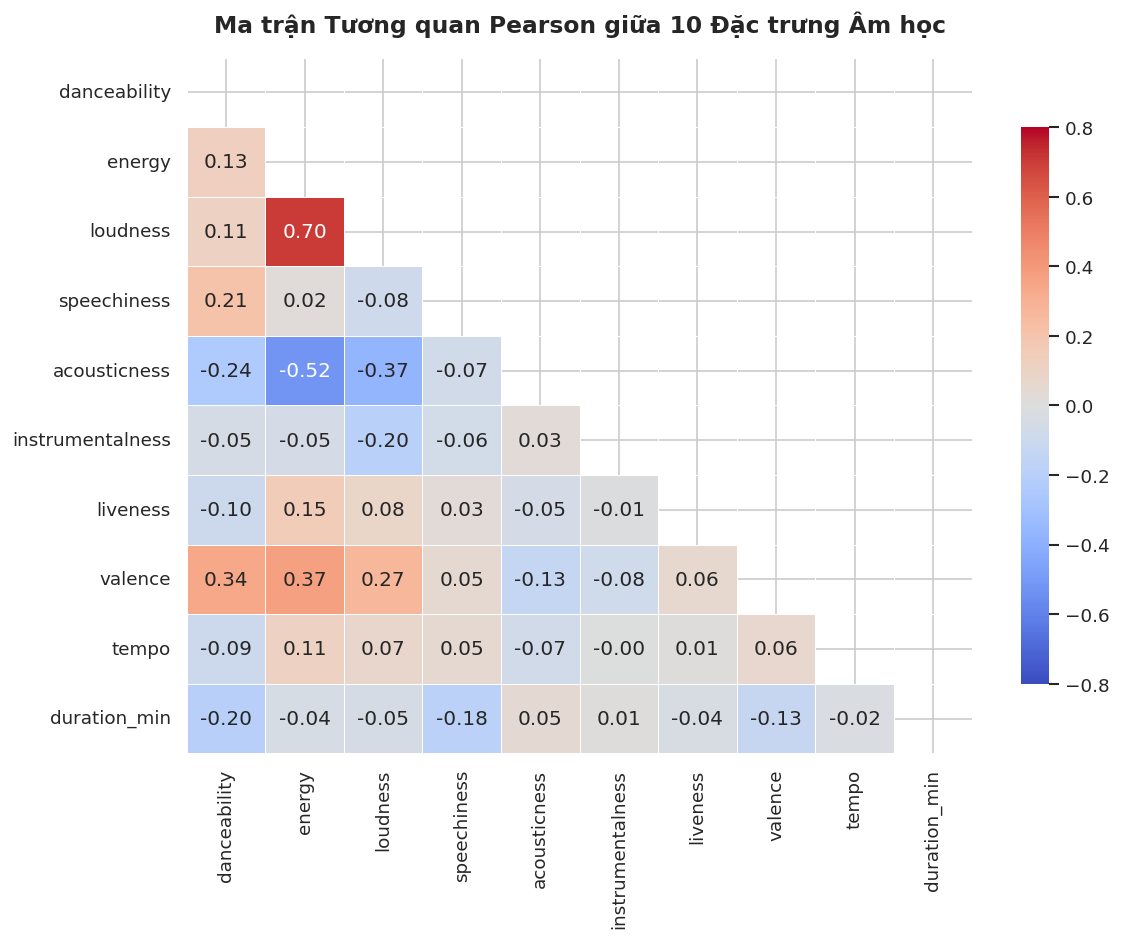

Điểm nhấn cộng tuyến: Tương quan giữa energy và loudness rất cao (r = 0.704).
VIF của energy = 2.67, VIF của loudness = 2.15.
Tương quan này cần được xem xét khi diễn giải sự đổi dấu của hệ số Energy.


In [18]:
# 1. Tính toán ma trận tương quan Pearson
corr_matrix = X.corr()

# 2. Tính hệ số VIF
def calculate_vif(df_features):
    from numpy.linalg import inv
    corr=df_features.corr().values
    inv_corr=inv(corr)
    vif_dict={df_features.columns[i]:inv_corr[i, i] for i in range(len(df_features.columns))}
    return pd.DataFrame(list(vif_dict.items()), columns=['Đặc trưng', 'Hệ số VIF']).sort_values(by='Hệ số VIF', ascending=False)

df_vif = calculate_vif(X)
print("BẢNG HỆ SỐ VIF:")
display(df_vif)

# 3. Heatmap tương quan
plt.figure(figsize=(10, 8))
mask=np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-0.8, 
    vmax=0.8,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Ma trận Tương quan Pearson giữa 10 Đặc trưng Âm học", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# Điểm nhấn tương quan giữa energy và loudness
r_el = corr_matrix.loc['energy', 'loudness']
print(f"Điểm nhấn cộng tuyến: Tương quan giữa energy và loudness rất cao (r = {r_el:.3f}).")
print(f"VIF của energy = {df_vif.loc[df_vif['Đặc trưng']=='energy', 'Hệ số VIF'].values[0]:.2f}, VIF của loudness = {df_vif.loc[df_vif['Đặc trưng']=='loudness', 'Hệ số VIF'].values[0]:.2f}.")
print("Tương quan này cần được xem xét khi diễn giải sự đổi dấu của hệ số Energy.")


## 4. PHÂN CHIA TẬP TRAIN / TEST & CHUẨN HÓA ĐẶC TRƯNG
- **80% Train:** 31,352 bài, dùng để học mối liên hệ giữa đặc trưng âm thanh và nhãn Hit.
- **20% Test:** 7,838 bài, dùng để đánh giá trên các bài không có trong tập huấn luyện.
- **Phân tầng (`stratify=y`):** Duy trì tỷ lệ Hit khoảng 13.94% ở cả hai tập; không biến dữ liệu thành hai lớp cân bằng 50/50.
- **Chuẩn hóa (`StandardScaler`):** Chỉ học trung bình và độ lệch chuẩn từ Train, sau đó áp dụng cùng phép biến đổi cho Test. Trung bình 0 và phương sai 1 áp dụng cho Train sau chuẩn hóa; Test không nhất thiết có các giá trị này.
- **Diễn giải hệ số:** Một đơn vị đặc trưng chuẩn hóa tương ứng một độ lệch chuẩn trên Train. Có thể so sánh độ lớn hệ số trong mô hình, nhưng không coi đó là mức quan trọng tuyệt đối, nhất là khi các đặc trưng tương quan.


In [19]:
# 1. Phân chia tập Train / Test có phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Khởi tạo và áp dụng StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Kích thước tập Train:{X_train.shape[0]:,} mẫu (Hit:{y_train.sum():,} | Non-Hit:{(len(y_train)-y_train.sum()):,})")
print(f"Kích thước tập Test: {X_test.shape[0]:,} mẫu (Hit:{y_test.sum():,} | Non-Hit:{(len(y_test)-y_test.sum()):,})")


Kích thước tập Train:31,352 mẫu (Hit:4,370 | Non-Hit:26,982)
Kích thước tập Test: 7,838 mẫu (Hit:1,093 | Non-Hit:6,745)


## 5. HUẤN LUYỆN MÔ HÌNH HỒI QUY LOGISTIC
* `class_weight='balanced'` đặt trọng số cao hơn cho lỗi ở lớp Hit thiểu số (khoảng 13.94%). Cấu hình này thay đổi hàm mục tiêu huấn luyện, không bảo đảm tối đa Recall hoặc F1.
* Dùng `solver='lbfgs'`, `max_iter=1000` và cấu hình `random_state=42`. Số vòng lặp tối đa không bảo đảm hội tụ; cần kiểm tra cảnh báo khi chạy.
* Điểm từ `predict_proba` được dùng để xếp hạng và phân lớp. Vì mô hình được huấn luyện với trọng số lớp, chưa nên diễn giải điểm này là xác suất Hit thực tế nếu chưa đánh giá hiệu chỉnh xác suất.


In [20]:
# 1. Khởi tạo mô hình Logistic Regression
model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced',
    solver='lbfgs'
)

# 2. Huấn luyện mô hình trên tập Train đã chuẩn hóa
model.fit(X_train_scaled, y_train)

# 3. Dự báo trên tập Test
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

### 5.1. Kiểm định ý nghĩa thống kê (p-value và Khoảng tin cậy 95%)

Dùng `statsmodels.sm.Logit` để khảo sát hệ số, p-value và khoảng tin cậy 95% trong một mô hình hồi quy bổ sung. Kiểm định xét giả thuyết hệ số bằng 0, có điều kiện theo các biến khác và các giả định của mô hình.

**Phân biệt hai mô hình:**
- Statsmodels ở mục này ước lượng Logit không có trọng số lớp và không dùng cấu hình regularization như mô hình dự báo.
- Scikit-learn ở mục 8 dùng `class_weight='balanced'` và regularization theo cấu hình của `LogisticRegression`.
- Hệ số có thể khác nhau. P-value của Statsmodels không phải p-value trực tiếp của các hệ số scikit-learn; mô hình bổ sung không thay thế đánh giá dự báo trên Test.

**Diễn giải p-value:**
- Với `tempo` (p khoảng 0.118), `valence` (p khoảng 0.138), `liveness` (p khoảng 0.315) và `instrumentalness` (p khoảng 0.169), chưa có đủ bằng chứng ở mức ý nghĩa 5% để kết luận hệ số khác 0 trong mô hình Statsmodels đang xét.
- P-value lớn không chứng minh đặc trưng không liên quan đến Hit. P-value nhỏ cũng không chứng minh quan hệ nhân quả hoặc bảo đảm dự báo tốt.
- Xem đồng thời độ lớn hệ số, khoảng tin cậy, tương quan giữa các biến và chất lượng dự báo; không suy ra thị hiếu thị trường chỉ từ p-value.


In [21]:
import statsmodels.api as sm
from IPython.display import display

# 1. Chuan bi du lieu voi he so chan (constant/intercept)
X_train_df = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)
X_train_sm = sm.add_constant(X_train_df)

# 2. Huan luyen mo hinh Logit voi statsmodels
logit_model = sm.Logit(y_train, X_train_sm).fit(disp=False)

# 3. Trich xuat bang he so, p-value va khoang tin cay 95%
conf = logit_model.conf_int()
df_stats = pd.DataFrame({
    'He so (Coef)': logit_model.params,
    'Sai so chuan (Std.Err)': logit_model.bse,
    'Gia tri z': logit_model.tvalues,
    'P-value': logit_model.pvalues,
    'CI 2.5%': conf.iloc[:, 0],
    'CI 97.5%': conf.iloc[:, 1]
})
df_stats['Y nghia (p < 0.05)'] = df_stats['P-value'].apply(
    lambda p: 'Co (p < 0.05)' if p < 0.05 else 'Khong (p >= 0.05)'
)

print('BANG KIEM DINH Y NGHIA THONG KE (STATSMODELS LOGIT SUMMARY):')
display(df_stats)

print()
print('Chi tiet tom tat mo hinh tu statsmodels:')
print(logit_model.summary())


BANG KIEM DINH Y NGHIA THONG KE (STATSMODELS LOGIT SUMMARY):


,He so (Coef),Sai so chuan (Std.Err),Gia tri z,P-value,CI 2.5%,CI 97.5%,Y nghia (p < 0.05)
const,-1.8701,0.0171,-109.5983,0.0000,-1.9035,-1.8367,Co (p < 0.05)
danceability,0.0814,0.0194,4.2014,0.0000,0.0435,0.1194,Co (p < 0.05)
energy,-0.1984,0.0271,-7.3257,0.0000,-0.2515,-0.1453,Co (p < 0.05)
loudness,0.3479,0.0259,13.4369,0.0000,0.2972,0.3987,Co (p < 0.05)
speechiness,-0.2032,0.0201,-10.1006,0.0000,-0.2426,-0.1637,Co (p < 0.05)
acousticness,0.0767,0.0198,3.8723,0.0001,0.0379,0.1156,Co (p < 0.05)
instrumentalness,-0.0281,0.0204,-1.3759,0.1689,-0.0680,0.0119,Khong (p >= 0.05)
liveness,-0.0174,0.0173,-1.0046,0.3151,-0.0512,0.0165,Khong (p >= 0.05)
valence,0.0286,0.0193,1.4834,0.1380,-0.0092,0.0663,Khong (p >= 0.05)
tempo,0.0266,0.0171,1.5613,0.1185,-0.0068,0.0601,Khong (p >= 0.05)



Chi tiet tom tat mo hinh tu statsmodels:
                           Logit Regression Results                           
Dep. Variable:                 is_hit   No. Observations:                31352
Model:                          Logit   Df Residuals:                    31341
Method:                           MLE   Df Model:                           10
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                 0.01854
Time:                        15:03:31   Log-Likelihood:                -12427.
converged:                       True   LL-Null:                       -12661.
Covariance Type:            nonrobust   LLR p-value:                 1.441e-94
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.8701      0.017   -109.598      0.000      -1.904      -1.837
danceability         0.0814      0.019      4.201      0.000       0.04

### 5.2. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix Heatmap) tại ngưỡng T = 0.50

Biểu đồ Heatmap 2x2 thể hiện chi tiết số lượng và tỷ lệ các ca khúc được phân loại đúng (True Negative, True Positive) và phân loại sai (False Positive, False Negative) trên tập Test ở ngưỡng phân lớp mặc định $T = 0.50$.

**Lưu ý về mẫu số:** Tỷ lệ (%) trong mỗi ô được tính trên toàn bộ 7,838 bài của tập Test, không phải theo từng lớp. Ví dụ, ô TP chiếm 657/7,838 = 8.38% tổng số bài Test; còn Recall = 657/(657 + 436) = 60.11% tính riêng trên 1,093 bài Hit thực tế. Hai tỷ lệ dùng mẫu số khác nhau nên không mâu thuẫn.

Chi tiet cac phan tu trong Ma tran nham lan tai nguong T = 0.50:
Tỷ lệ (%) bên dưới tính trên toàn bộ 7,838 bài Test, không phải theo từng lớp.
 True Negatives (TN):  3,669 (46.81%) - Du doan dung Non-Hit
 False Positives (FP): 3,076 (39.24%) - Bao dong nham la Hit
 False Negatives (FN): 436 (5.56%) - Bo sot bai Hit thuc te
 True Positives (TP):  657 (8.38%) - Bat trung bai Hit thuc te

 Accuracy:             55.19%
 Precision:            17.60%
 Recall:               60.11%
 F1-Score:             27.23%
 ROC-AUC:              0.5906


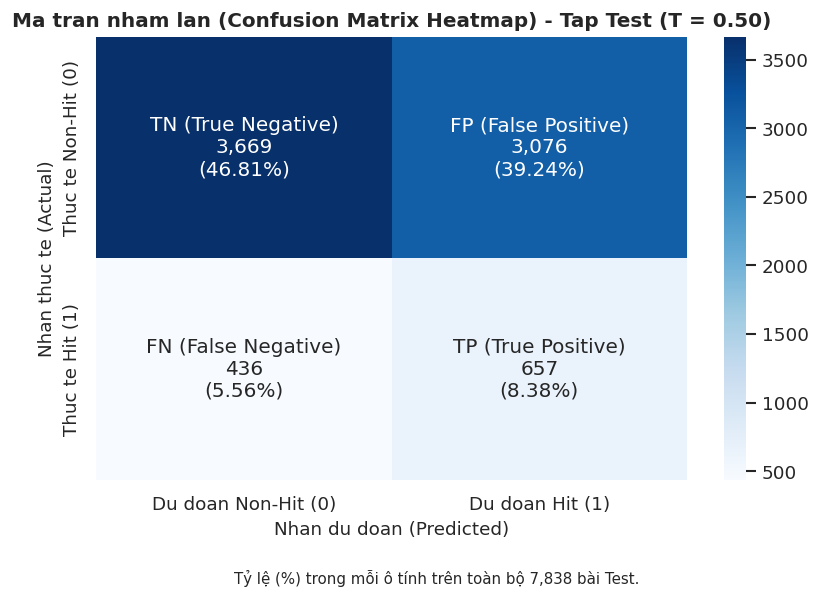

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Kiem tra va dam bao y_pred va y_proba san sang
if 'y_pred' not in locals() or 'y_proba' not in locals():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

# 2. Tinh toan cac chi so danh gia cot loi tai nguong mac dinh T = 0.50
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# 3. Truc quan hoa Ma tran nham lan Heatmap 2x2
plt.figure(figsize=(7, 5))
labels = [
    [f'TN (True Negative)\n{tn:,}\n({tn/len(y_test)*100:.2f}%)', f'FP (False Positive)\n{fp:,}\n({fp/len(y_test)*100:.2f}%)'],
    [f'FN (False Negative)\n{fn:,}\n({fn/len(y_test)*100:.2f}%)', f'TP (True Positive)\n{tp:,}\n({tp/len(y_test)*100:.2f}%)']
]

sns.heatmap(
    cm,
    annot=labels,
    fmt='',
    cmap='Blues',
    cbar=True,
    xticklabels=['Du doan Non-Hit (0)', 'Du doan Hit (1)'],
    yticklabels=['Thuc te Non-Hit (0)', 'Thuc te Hit (1)']
)
plt.title('Ma tran nham lan (Confusion Matrix Heatmap) - Tap Test (T = 0.50)', fontsize=12, fontweight='bold')
plt.xlabel('Nhan du doan (Predicted)')
plt.ylabel('Nhan thuc te (Actual)')
plt.figtext(0.5, 0.01, f'Tỷ lệ (%) trong mỗi ô tính trên toàn bộ {len(y_test):,} bài Test.', ha='center', fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print('Chi tiet cac phan tu trong Ma tran nham lan tai nguong T = 0.50:')
print(f'Tỷ lệ (%) bên dưới tính trên toàn bộ {len(y_test):,} bài Test, không phải theo từng lớp.')
print(f' True Negatives (TN):  {tn:,} ({tn/len(y_test)*100:.2f}%) - Du doan dung Non-Hit')
print(f' False Positives (FP): {fp:,} ({fp/len(y_test)*100:.2f}%) - Bao dong nham la Hit')
print(f' False Negatives (FN): {fn:,} ({fn/len(y_test)*100:.2f}%) - Bo sot bai Hit thuc te')
print(f' True Positives (TP):  {tp:,} ({tp/len(y_test)*100:.2f}%) - Bat trung bai Hit thuc te')
print()
print(f' Accuracy:             {acc*100:.2f}%')
print(f' Precision:            {prec*100:.2f}%')
print(f' Recall:               {rec*100:.2f}%')
print(f' F1-Score:             {f1*100:.2f}%')
print(f' ROC-AUC:              {roc_auc:.4f}')


### 5.3. Đường Precision-Recall và Average Precision (AP)

Với lớp Hit chiếm khoảng 13.94% trong Test, đường Precision-Recall cho thấy sự đánh đổi giữa mức phát hiện Hit và độ chính xác của các dự đoán Hit. Average Precision (AP) tóm tắt Precision theo mức tăng Recall trên toàn bộ ngưỡng.

AP được tính bằng `average_precision_score`, không đồng nhất với diện tích nội suy hình thang dưới đường Precision-Recall. Đường ngang ở tỷ lệ Hit trong Test là mốc tham chiếu cho xếp hạng không có khả năng phân biệt; AP cao hơn mốc này cho thấy cải thiện trong tập Test, không phải tỷ lệ dự đoán đúng hoặc bảo đảm hiệu quả kinh doanh.

Cell bên dưới đánh giá điểm dự đoán đã có, không huấn luyện lại hoặc chọn ngưỡng mới. Không suy ra AP từ ROC-AUC hay ma trận nhầm lẫn.

**Dữ liệu đầu vào:** `data/processed/ml_tracks.csv` gồm 39,190 bài hát, trong đó có 5,463 bài Hit; các cột đầu vào và nhãn khớp với bản Parquet. Kết quả AP và mốc tỷ lệ Hit trong Test được tính trực tiếp trong cell bên dưới. AP không phải Accuracy; nếu dữ liệu đầu vào thay đổi, cần chạy lại toàn bộ notebook và cập nhật các con số trong phần tổng kết.


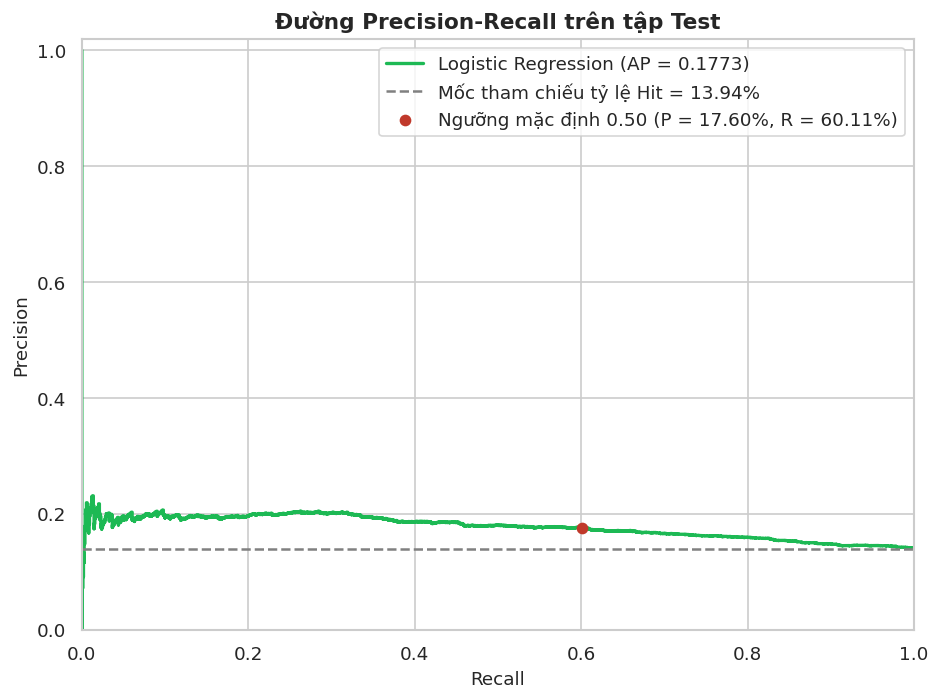

Average Precision (AP): 0.1773
Mốc tham chiếu tỷ lệ Hit trong Test: 0.1394 (13.94%)
Chênh lệch AP so với mốc tham chiếu: +0.0379


In [23]:
pr_precision, pr_recall, _ = precision_recall_curve(y_test, y_proba)
avg_precision = average_precision_score(y_test, y_proba)
hit_baseline = float(y_test.mean())

plt.figure(figsize=(8, 6))
plt.step(
    pr_recall, pr_precision, where='post', color='#1DB954', lw=2,
    label=f'Logistic Regression (AP = {avg_precision:.4f})'
)
plt.axhline(
    hit_baseline, color='gray', linestyle='--',
    label=f'Mốc tham chiếu tỷ lệ Hit = {hit_baseline:.2%}'
)
plt.scatter(
    [rec], [prec], color='#c0392b', zorder=3,
    label=f'Ngưỡng mặc định 0.50 (P = {prec:.2%}, R = {rec:.2%})'
)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Đường Precision-Recall trên tập Test')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f'Average Precision (AP): {avg_precision:.4f}')
print(f'Mốc tham chiếu tỷ lệ Hit trong Test: {hit_baseline:.4f} ({hit_baseline:.2%})')
print(f'Chênh lệch AP so với mốc tham chiếu: {avg_precision - hit_baseline:+.4f}')


## 6. Khảo sát biến thiên theo ngưỡng phân lớp

Khảo sát Precision, Recall, F1 và Accuracy khi thay đổi ngưỡng trên điểm dự đoán. Ngưỡng 0.50 là cấu hình mặc định để báo cáo, không mặc nhiên là ngưỡng tối ưu F1.

Các ngưỡng 0.40, 0.50 và 0.60 minh họa sự đánh đổi giữa phát hiện Hit và báo động nhầm, chưa phải khuyến nghị đầu tư đã được kiểm chứng. Việc tìm F1 cao nhất trên Test chỉ mang tính khám phá; nếu chọn ngưỡng sử dụng chính thức, cần chọn trên Validation hoặc bằng cross-validation, rồi đánh giá trên Test độc lập.


BẢNG SO SÁNH 3 NGƯỠNG PHÂN LỚP MINH HỌA TRÊN TEST:


,Cấu hình,Ngưỡng T,Accuracy,Precision,Recall,Mục đích minh họa
0,Ưu tiên Recall,0.40,26.70%,14.81%,89.57%,Minh họa ưu tiên phát hiện Hit
1,Ngưỡng mặc định,0.50,55.19%,17.60%,60.11%,Minh họa phân lớp tại ngưỡng mặc định
2,Ngưỡng cao hơn,0.60,80.77%,19.29%,11.89%,Minh họa phân lớp với ngưỡng cao hơn


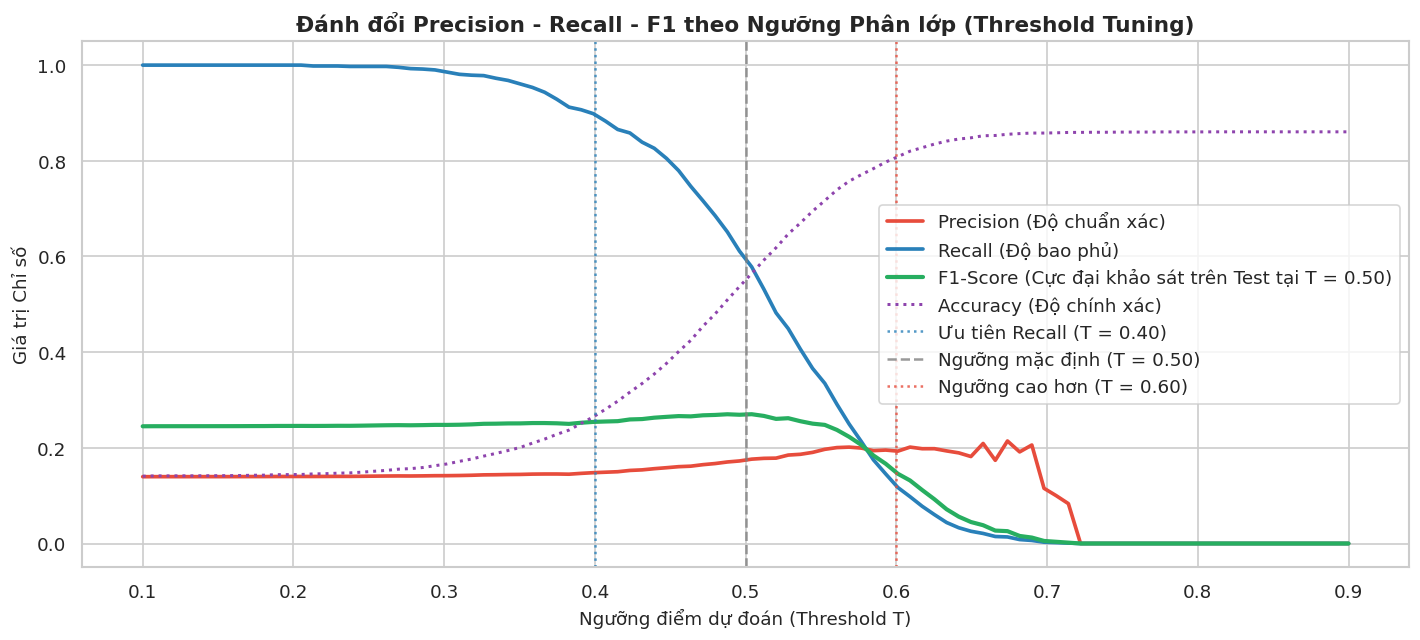

In [24]:
# 1. Khảo sát biến thiên Precision, Recall, F1 theo Threshold
threshold_range=np.linspace(0.10, 0.90, 100)
accuracies, precisions, recalls, f1_list = [], [], [], []

for t in threshold_range:
    pred_t=(y_proba >= t).astype(int)
    accuracies.append(accuracy_score(y_test, pred_t))
    precisions.append(precision_score(y_test, pred_t, zero_division=0))
    recalls.append(recall_score(y_test, pred_t, zero_division=0))
    f1_list.append(f1_score(y_test, pred_t, zero_division=0))

best_idx=np.argmax(f1_list)
opt_threshold=threshold_range[best_idx]
best_f1=f1_list[best_idx]

# 2. So sánh 3 ngưỡng minh họa trên tập Test
target_thresholds=[0.40, 0.50, 0.60]
strat_names=['Ưu tiên Recall', 'Ngưỡng mặc định', 'Ngưỡng cao hơn']
strat_apps=[
    'Minh họa ưu tiên phát hiện Hit',
    'Minh họa phân lớp tại ngưỡng mặc định',
    'Minh họa phân lớp với ngưỡng cao hơn'
]

strat_rows=[]
for name, t_val, app in zip(strat_names, target_thresholds, strat_apps):
    p_t=(y_proba >= t_val).astype(int)
    strat_rows.append({
        'Cấu hình':name,
        'Ngưỡng T':f"{t_val:.2f}",
        'Accuracy':f"{accuracy_score(y_test, p_t)*100:.2f}%",
        'Precision':f"{precision_score(y_test, p_t, zero_division=0)*100:.2f}%",
        'Recall': f"{recall_score(y_test, p_t, zero_division=0)*100:.2f}%",
        'Mục đích minh họa': app
    })

df_strategies = pd.DataFrame(strat_rows)
print("BẢNG SO SÁNH 3 NGƯỠNG PHÂN LỚP MINH HỌA TRÊN TEST:")
display(df_strategies)

# 3. Trực quan hóa Precision - Recall - F1 Trade-off Curve
plt.figure(figsize=(12, 5.5))
plt.plot(threshold_range, precisions, color='#e74c3c', lw=2.2, label='Precision (Độ chuẩn xác)')
plt.plot(threshold_range, recalls, color='#2980b9', lw=2.2, label='Recall (Độ bao phủ)')
plt.plot(threshold_range, f1_list, color='#27ae60', lw=2.5, linestyle='-', label=f'F1-Score (Cực đại khảo sát trên Test tại T = {opt_threshold:.2f})')
plt.plot(threshold_range, accuracies, color='#8e44ad', lw=1.8, linestyle=':', label='Accuracy (Độ chính xác)')

plt.axvline(x=0.40, color='#2980b9', linestyle=':', alpha=0.8, label='Ưu tiên Recall (T = 0.40)')
plt.axvline(x=0.50, color='gray', linestyle='--', alpha=0.8, label='Ngưỡng mặc định (T = 0.50)')
plt.axvline(x=0.60, color='#e74c3c', linestyle=':', alpha=0.8, label='Ngưỡng cao hơn (T = 0.60)')

plt.title("Đánh đổi Precision - Recall - F1 theo Ngưỡng Phân lớp (Threshold Tuning)", fontsize=13, fontweight='bold')
plt.xlabel("Ngưỡng điểm dự đoán (Threshold T)")
plt.ylabel("Giá trị Chỉ số")
plt.legend(loc='center right', frameon=True)
plt.tight_layout()
plt.show()


## 7. KHẢO SÁT SỰ ĐỔI DẤU CỦA HỆ SỐ ENERGY

Trong mô hình 10 đặc trưng, `energy` có hệ số khoảng -0.1943 (Odds Ratio khoảng 0.823). Đây là mối liên hệ có điều kiện khi giữ các đặc trưng khác cố định, không phải kết luận tổng quát rằng nhạc sôi động ít có khả năng thành Hit.

Thực nghiệm bỏ biến bên dưới so sánh mô hình đầy đủ với mô hình bỏ `loudness` và mô hình bỏ `energy`. Mục tiêu là khảo sát độ nhạy của hệ số khi thay đổi tập biến, đặc biệt do `energy` và `loudness` tương quan thuận (r khoảng 0.704).


KẾT QUẢ THỰC NGHIỆM BÓC TÁCH ĐẶC TRƯNG


,Mô hình Thực nghiệm,β(energy),β(loudness),ROC-AUC
0,Model A (Đầy đủ 10 biến),-0.1943,+0.3423,0.5906
1,"Model B (Bỏ Loudness, giữ Energy)",+0.0332 (Đảo dấu),N/A (Đã bỏ),0.5611
2,"Model C (Bỏ Energy, giữ Loudness)",N/A (Đã bỏ),+0.2306,0.5807


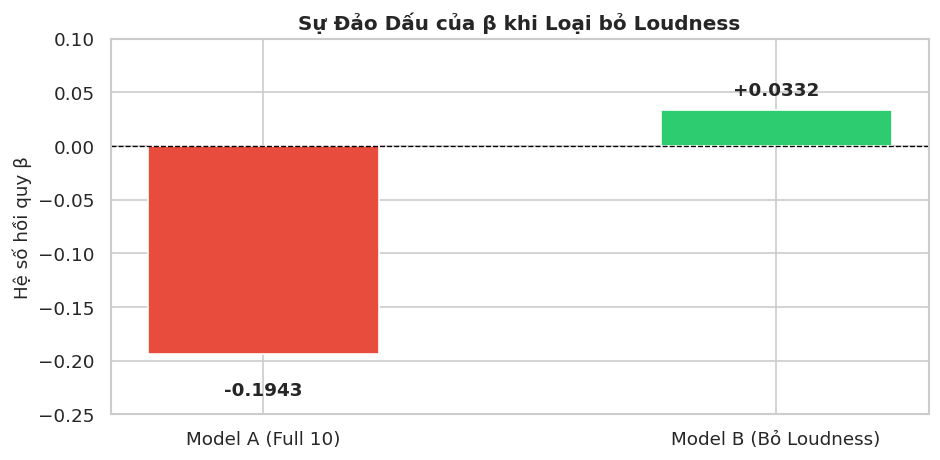

In [25]:
# Huấn luyện 3 mô hình bóc tách để kiểm chứng
feats_A = feature_cols
feats_B = [f for f in feature_cols if f != 'loudness']
feats_C = [f for f in feature_cols if f != 'energy']

# Model A (Full 10 Features)
mA = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
mA.fit(X_train_scaled, y_train)

# Model B (No Loudness)
idx_B = [feature_cols.index(f) for f in feats_B]
mB = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
mB.fit(X_train_scaled[:, idx_B], y_train)

# Model C (No Energy)
idx_C = [feature_cols.index(f) for f in feats_C]
mC = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
mC.fit(X_train_scaled[:, idx_C], y_train)

# Tổng hợp hệ số và AUC
coef_energy_A = mA.coef_[0][feature_cols.index('energy')]
coef_loudness_A = mA.coef_[0][feature_cols.index('loudness')]

coef_energy_B = mB.coef_[0][feats_B.index('energy')]
coef_loudness_C = mC.coef_[0][feats_C.index('loudness')]

auc_A = roc_auc_score(y_test, mA.predict_proba(X_test_scaled)[:, 1])
auc_B = roc_auc_score(y_test, mB.predict_proba(X_test_scaled[:, idx_B])[:, 1])
auc_C = roc_auc_score(y_test, mC.predict_proba(X_test_scaled[:, idx_C])[:, 1])

df_ablation = pd.DataFrame({
    'Mô hình Thực nghiệm': [
        'Model A (Đầy đủ 10 biến)', 
        'Model B (Bỏ Loudness, giữ Energy)', 
        'Model C (Bỏ Energy, giữ Loudness)'
    ],
    'β(energy)': [f"{coef_energy_A:+.4f}", f"{coef_energy_B:+.4f} (Đảo dấu)", "N/A (Đã bỏ)"],
    'β(loudness)': [f"{coef_loudness_A:+.4f}", "N/A (Đã bỏ)", f"{coef_loudness_C:+.4f}"],
    'ROC-AUC': [f"{auc_A:.4f}", f"{auc_B:.4f}", f"{auc_C:.4f}"]
})

print("KẾT QUẢ THỰC NGHIỆM BÓC TÁCH ĐẶC TRƯNG")
display(df_ablation)

# Trực quan hóa sự đảo dấu của beta
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['Model A (Full 10)', 'Model B (Bỏ Loudness)'], [coef_energy_A, coef_energy_B], 
              color=['#e74c3c', '#2ecc71'], width=0.45)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_ylabel("Hệ số hồi quy β")
ax.set_title("Sự Đảo Dấu của β khi Loại bỏ Loudness", fontsize=12, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + (0.01 if yval > 0 else -0.025), 
            f"{yval:+.4f}", ha='center', va='bottom' if yval > 0 else 'top', fontweight='bold', fontsize=11)

plt.ylim(-0.25, 0.10)
plt.tight_layout()
plt.show()


### KẾT LUẬN VỀ THỰC NGHIỆM BỎ BIẾN

1. Khi bỏ `loudness`, hệ số `energy` chuyển từ khoảng -0.1943 sang +0.0332. Mô hình còn 9 đặc trưng; đây không phải hồi quy chỉ dùng riêng `energy`.
2. Sự đổi dấu phù hợp với việc hệ số phụ thuộc vào tập biến tương quan cùng có mặt trong mô hình. Nó không chứng minh `energy` về bản chất thúc đẩy thành công.
3. Dữ liệu và thực nghiệm hiện tại không đo trực tiếp dynamic range, mức nén âm hoặc cảm giác mệt tai. Vì vậy, chưa đủ bằng chứng để quy hệ số âm cho cơ chế nén âm quá mức.


## 8. PHÂN TÍCH HỆ SỐ HỒI QUY & TỶ SỐ CHÊNH

Với điểm dự đoán $p$ của mô hình, $\text{odds} = p / (1 - p)$. Khi một đặc trưng chuẩn hóa tăng 1 đơn vị (một độ lệch chuẩn trên Train), giữ các đặc trưng khác cố định, odds ước lượng được nhân với $e^{\beta_i}$.

- $e^{\beta_i} > 1$: Liên quan đến odds ước lượng cao hơn.
- $e^{\beta_i} < 1$: Liên quan đến odds ước lượng thấp hơn.
- Phần trăm thay đổi **odds**: $(e^{\beta_i} - 1) \times 100\%$, không phải phần trăm thay đổi xác suất hoặc số điểm phần trăm xác suất.

Các hệ số mô tả mối liên hệ trong mô hình có trọng số lớp, chưa phải tác động nhân quả hoặc mức thay đổi xác suất Hit thực tế.


BẢNG HỆ SỐ HỒI QUY VÀ TỶ SỐ CHÊNH (ODDS RATIO) CỦA 10 ĐẶC TRƯNG ÂM HỌC:


,Đặc trưng,Hệ số β,Odds Ratio e^β,Thay đổi odds (%),Diễn giải
0,loudness,0.3423,1.4082,40.8190,Liên hệ với odds cao hơn (+40.8%)
1,duration_min,0.1534,1.1658,16.5771,Liên hệ với odds cao hơn (+16.6%)
2,acousticness,0.0872,1.0911,9.1086,Liên hệ với odds cao hơn (+9.1%)
3,danceability,0.0827,1.0862,8.6172,Liên hệ với odds cao hơn (+8.6%)
4,valence,0.0308,1.0313,3.1266,Liên hệ với odds cao hơn (+3.1%)
5,tempo,0.0297,1.0301,3.0122,Liên hệ với odds cao hơn (+3.0%)
6,liveness,-0.0167,0.9835,-1.6519,Liên hệ với odds thấp hơn (-1.7%)
7,instrumentalness,-0.0227,0.9775,-2.2453,Liên hệ với odds thấp hơn (-2.2%)
8,energy,-0.1943,0.8234,-17.6570,Liên hệ với odds thấp hơn; nhạy với tập biến (...
9,speechiness,-0.2038,0.8157,-18.4339,Liên hệ với odds thấp hơn (-18.4%)


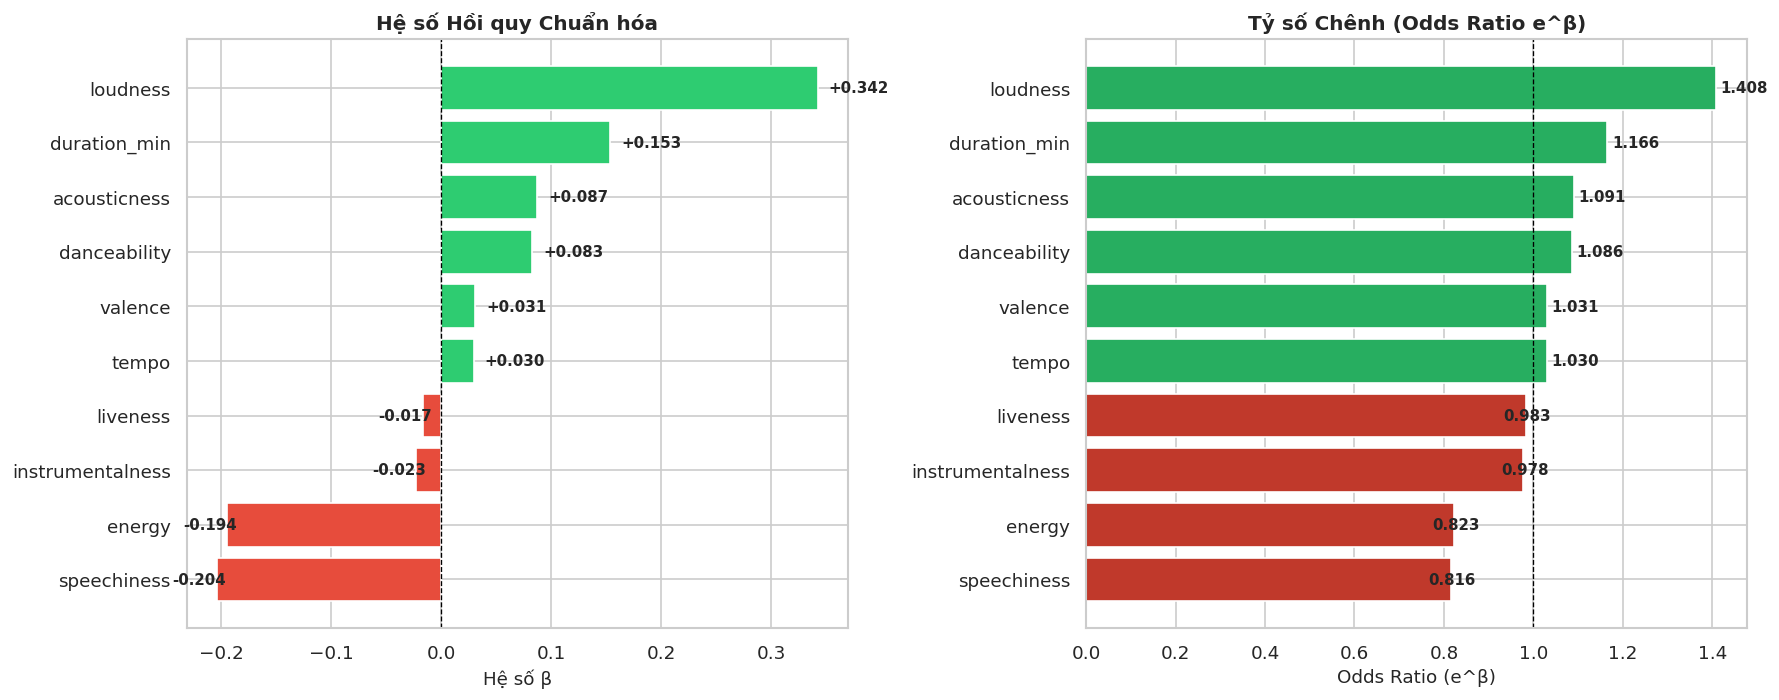

In [26]:
# 1. Trích xuất hệ số Beta và tính Tỷ số chênh Odds Ratio
df_odds = pd.DataFrame({
    'Đặc trưng': feature_cols,
    'Hệ số β': model.coef_[0],
    'Odds Ratio e^β': np.exp(model.coef_[0]),
    'Thay đổi odds (%)': (np.exp(model.coef_[0]) - 1) * 100
})

def categorize_impact(row):
    feat = row['Đặc trưng']
    b = row['Hệ số β']
    pct = row['Thay đổi odds (%)']
    if feat == 'energy':
        return f"Liên hệ với odds thấp hơn; nhạy với tập biến ({pct:+.1f}%)"
    if b > 0.20:
        return f"Liên hệ với odds cao hơn ({pct:+.1f}%)"
    elif b > 0.10:
        return f"Liên hệ với odds cao hơn ({pct:+.1f}%)"
    elif b > 0:
        return f"Liên hệ với odds cao hơn ({pct:+.1f}%)"
    elif b < -0.15:
        return f"Liên hệ với odds thấp hơn ({pct:+.1f}%)"
    else:
        return f"Liên hệ với odds thấp hơn ({pct:+.1f}%)"

df_odds['Diễn giải'] = df_odds.apply(categorize_impact, axis=1)
df_odds = df_odds.sort_values(by='Hệ số β', ascending=False).reset_index(drop=True)

print("BẢNG HỆ SỐ HỒI QUY VÀ TỶ SỐ CHÊNH (ODDS RATIO) CỦA 10 ĐẶC TRƯNG ÂM HỌC:")
display(df_odds)

# 2. Trực quan hóa Biểu đồ Thanh ngang Hệ số Hồi quy & Odds Ratio
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Beta Coefficients
colors_beta = ['#2ecc71' if b > 0 else '#e74c3c' for b in df_odds['Hệ số β']]
axes[0].barh(df_odds['Đặc trưng'], df_odds['Hệ số β'], color=colors_beta)
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title("Hệ số Hồi quy Chuẩn hóa", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Hệ số β")
axes[0].invert_yaxis()

for i, v in enumerate(df_odds['Hệ số β']):
    axes[0].text(v + (0.01 if v > 0 else -0.04), i, f"{v:+.3f}", va='center', fontweight='bold', fontsize=9)

# Subplot 2: Odds Ratio
colors_or = ['#27ae60' if r > 1.0 else '#c0392b' for r in df_odds['Odds Ratio e^β']]
axes[1].barh(df_odds['Đặc trưng'], df_odds['Odds Ratio e^β'], color=colors_or)
axes[1].axvline(1.0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_title("Tỷ số Chênh (Odds Ratio e^β)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Odds Ratio (e^β)")
axes[1].invert_yaxis()

for i, v in enumerate(df_odds['Odds Ratio e^β']):
    axes[1].text(v + (0.01 if v > 1.0 else -0.05), i, f"{v:.3f}", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


### MỐI LIÊN HỆ GIỮA ĐẶC TRƯNG ÂM HỌC VÀ NHÃN HIT

Các diễn giải sau áp dụng khi tăng một độ lệch chuẩn trên Train và giữ các đặc trưng khác cố định:

1. **`loudness` (beta khoảng +0.3423, Odds Ratio khoảng 1.408):** Odds ước lượng cao hơn khoảng 40.8%. Đây là hệ số dương lớn nhất trong 10 đặc trưng chuẩn hóa, không chứng minh tăng âm lượng sẽ tạo Hit.
2. **`duration_min` (beta khoảng +0.1534, Odds Ratio khoảng 1.166):** Odds ước lượng cao hơn khoảng 16.6%. Hệ số tuyến tính này không xác định một khoảng thời lượng tối ưu như 3.0-3.5 phút.
3. **`speechiness` (beta khoảng -0.2038, Odds Ratio khoảng 0.816):** Odds ước lượng thấp hơn khoảng 18.4%. Chưa thể suy ra việc giảm lời rap sẽ làm bài hát thành công hơn.
4. **`danceability` (beta khoảng +0.0827, Odds Ratio khoảng 1.086):** Odds ước lượng cao hơn khoảng 8.6%. Notebook không có dữ liệu TikTok để kiểm chứng cơ chế lan truyền trên nền tảng này.

Các kết quả là mối liên hệ thống kê trong tập bài hát đã vào bảng xếp hạng, không phải công thức sản xuất bảo đảm thành công.


## 9. SO SÁNH VỚI MÔ HÌNH PHI TUYẾN

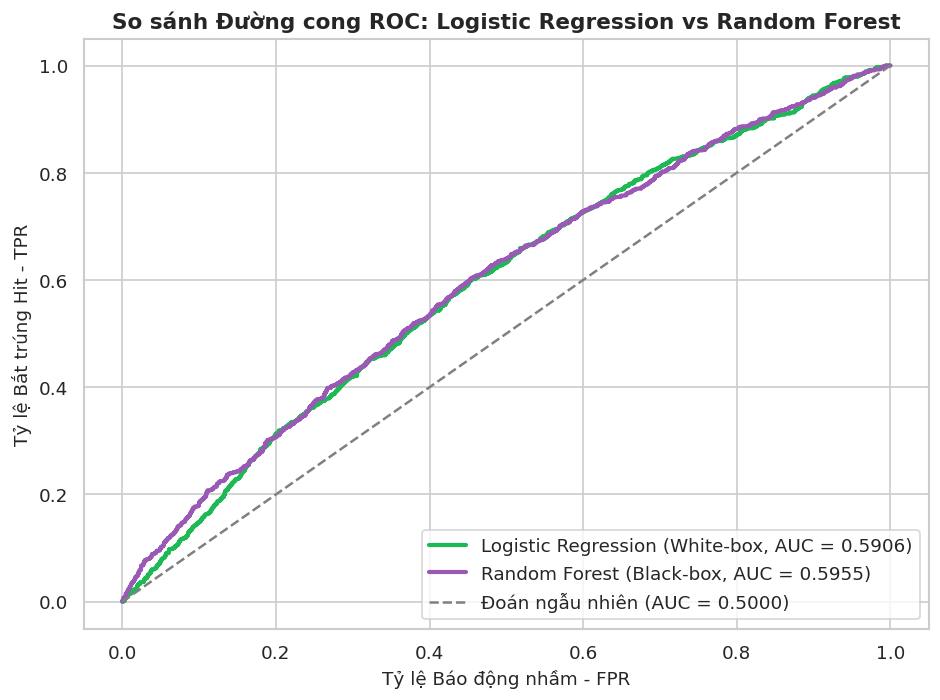

Logistic Regression ROC-AUC:0.5906 (White-box)
Random Forest ROC-AUC:      0.5955 (Black-box)


In [27]:
# 1. Huấn luyện Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# 2. Dự báo xác suất
rf_proba = rf_model.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_proba)

# 3. Vẽ biểu đồ so sánh ROC Curve
plt.figure(figsize=(8, 6))
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)

plt.plot(fpr_lr, tpr_lr, color='#1DB954', lw=2.5, label=f'Logistic Regression (White-box, AUC = {roc_auc:.4f})')
plt.plot(fpr_rf, tpr_rf, color='#9b59b6', lw=2.5, label=f'Random Forest (Black-box, AUC = {rf_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Đoán ngẫu nhiên (AUC = 0.5000)')

plt.title("So sánh Đường cong ROC: Logistic Regression vs Random Forest", fontsize=13, fontweight='bold')
plt.xlabel("Tỷ lệ Báo động nhầm - FPR")
plt.ylabel("Tỷ lệ Bắt trúng Hit - TPR")
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

print(f"Logistic Regression ROC-AUC:{roc_auc:.4f} (White-box)")
print(f"Random Forest ROC-AUC:      {rf_auc:.4f} (Black-box)")


### Diễn giải ROC-AUC và so sánh hai mô hình

Logistic Regression đạt ROC-AUC khoảng **0.5906**, còn Random Forest đạt khoảng **0.5955**. Chênh lệch khoảng **0.0048 AUC** là cải thiện nhỏ trong cấu hình thử nghiệm này; chưa có đánh giá bất định để kết luận chênh lệch có ý nghĩa thống kê.

ROC-AUC đo khả năng xếp hạng phân biệt hai lớp, không phải tỷ lệ dự đoán đúng và không đo phần đóng góp của âm thanh vào thành công. Kết quả cao hơn mốc xếp hạng ngẫu nhiên 0.5 nhưng cho thấy khả năng phân biệt còn hạn chế.

Hai thử nghiệm chưa đủ để xác định trần dự báo của dữ liệu. Không thể suy ra âm thanh quyết định 10-15% thành công hay các yếu tố khác quyết định 85%. Danh tiếng nghệ sĩ, marketing, playlist và mạng xã hội có thể là hướng bổ sung dữ liệu, nhưng đóng góp của chúng chưa được đo trong notebook.

Việc loại các biến dùng tạo nhãn khỏi đầu vào giúp hạn chế rò rỉ trực tiếp. AUC thấp tự nó không chứng minh mô hình không có rò rỉ hoặc đã phản ánh đầy đủ thực tế.


## 10. BỘ CÔNG CỤ GIẢ LẬP HIT SIMULATOR

Simulator minh họa điểm dự đoán và đóng góp vào log-odds của các đặc trưng cho một bản thu giả định. Đóng góp được tính trong mô hình, không phải mức đóng góp nhân quả vào thành công.

Các gợi ý hiển thị dựa trên điều kiện đặt thủ công để khảo sát thêm; các ngưỡng này chưa được tối ưu hoặc kiểm chứng như quy tắc sản xuất. Điểm từ mô hình chưa được hiệu chỉnh thành xác suất Hit thực tế. Simulator không bảo đảm chất lượng âm nhạc, an toàn nghe hoặc thành công thương mại.


In [28]:
def simulate_track_hit(params_dict, threshold=0.50):
    """
    Minh họa điểm dự đoán Hit và các gợi ý khảo sát, chưa kiểm chứng nhân quả.
    """
    input_data = pd.DataFrame([{col: params_dict[col] for col in feature_cols}])
    input_scaled = scaler.transform(input_data)
    prob = model.predict_proba(input_scaled)[0, 1]
    is_hit = bool(prob >= threshold)
    
    # Tính toán đóng góp của từng đặc trưng
    contributions = input_scaled[0] * model.coef_[0]
    df_contrib = pd.DataFrame({
        'Feature': feature_cols,
        'Value': [params_dict[c] for c in feature_cols],
        'Contribution': contributions
    }).sort_values(by='Contribution', ascending=False)
    
    # Gợi ý khảo sát từ các điều kiện đặt thủ công, chưa phải ngưỡng tối ưu
    recommendations = []
    if params_dict.get('loudness', -10) < -7.0:
        recommendations.append("Loudness dưới -7 dB. Có thể khảo sát điểm dự đoán khi thay đổi loudness và giữ các biến khác cố định; mô hình chưa xác định mức âm lượng tối ưu hoặc mức tăng xác suất thực tế.")
    if params_dict.get('speechiness', 0.1) > 0.20:
        recommendations.append("Speechiness trên 0.20. Hệ số âm thể hiện mối liên hệ có điều kiện trong mô hình; chưa chứng minh giảm lời nói hoặc rap sẽ làm bài hát thành công hơn.")
    if params_dict.get('duration_min', 3.0) < 2.5:
        recommendations.append("Thời lượng dưới 2.5 phút. Có thể khảo sát độ nhạy của điểm dự đoán theo thời lượng; mô hình chưa xác định khoảng thời lượng tối ưu hoặc cấu trúc bài hát cần có.")
    if params_dict.get('energy', 0.6) > 0.85 and params_dict.get('loudness', -6) > -5.0:
        recommendations.append("Energy trên 0.85 và loudness trên -5 dB. Hai đặc trưng tương quan nên cần diễn giải đồng thời; các giá trị này không đủ để kết luận bản thu bị nén âm quá mức hoặc gây mệt tai.")
        
    if not recommendations:
        recommendations.append("Không có gợi ý từ các điều kiện khảo sát đặt thủ công; điều này không xác nhận chất lượng bản thu hoặc khả năng thành Hit.")
        
    return {
        'hit_probability': prob,
        'prediction': 'Hit' if is_hit else 'Non-Hit',
        'threshold_used': threshold,
        'feature_contributions': df_contrib,
        'recommendations': recommendations
    }

# Thử nghiệm giả lập với một ca khúc mẫu
sample_track = {
    'danceability': 0.75,
    'energy': 0.65,
    'loudness': -5.8,
    'speechiness': 0.06,
    'acousticness': 0.20,
    'instrumentalness': 0.00,
    'liveness': 0.12,
    'valence': 0.68,
    'tempo': 122.0,
    'duration_min': 3.25
}

result = simulate_track_hit(sample_track, threshold=0.50)
print(f"KẾT QUẢ GIẢ LẬP CA KHÚC:")
print(f"Điểm dự đoán từ mô hình: {result['hit_probability']*100:.2f}%")
print(f"Kết luận dự báo:   {result['prediction']}")
print(f"\nGợi ý khảo sát (chưa kiểm chứng):")
for item in result['recommendations']:
     print(f"{item}")


KẾT QUẢ GIẢ LẬP CA KHÚC:
Điểm dự đoán từ mô hình: 55.78%
Kết luận dự báo:   Hit

Gợi ý khảo sát (chưa kiểm chứng):
Không có gợi ý từ các điều kiện khảo sát đặt thủ công; điều này không xác nhận chất lượng bản thu hoặc khả năng thành Hit.


## 11. TỔNG KẾT VỀ MÔ HÌNH HỌC MÁY

### 11.1. Đánh giá kết quả mô hình Logistic Regression

Mô hình phân loại nhãn Hit theo định nghĩa `pop_score >= 50` từ 10 đặc trưng âm học. Các kết quả trên Test tại ngưỡng mặc định 0.50:

| Chỉ số | Giá trị | Diễn giải |
| :--- | :--- | :--- |
| Recall | 60.11% | Phát hiện đúng 657/1,093 bài Hit; bỏ sót 436 bài. |
| Precision | 17.60% | Trong 3,733 bài được dự đoán Hit, 657 bài đúng và 3,076 bài là báo động nhầm. |
| F1 | 27.23% | Trung bình điều hòa của Precision và Recall; hiệu quả nhận diện Hit còn hạn chế. |
| Accuracy | 55.19% | Tỷ lệ dự đoán đúng trên toàn bộ Test. |
| ROC-AUC | 0.5906 | Khả năng xếp hạng phân biệt hai lớp còn hạn chế; không phải tỷ lệ dự đoán đúng. |
| Average Precision (AP) | 0.1773 | Tính trên Test từ dữ liệu hiện tại; mốc tỷ lệ Hit là 0.1394. Xem mục 5.3. |

Nếu luôn đoán Non-Hit, Accuracy trên Test đạt khoảng 86.06% nhưng Recall của lớp Hit bằng 0. Vì vậy, cần xem đồng thời Precision, Recall, F1 và ROC-AUC. Precision của mô hình cao hơn tỷ lệ Hit khoảng 13.94% trong Test, nhưng đa số bài được dự đoán Hit vẫn là báo động nhầm. `class_weight='balanced'` tăng trọng số lỗi ở lớp Hit, không bảo đảm tối đa Recall.

### 11.2. Các mối liên hệ âm học được ghi nhận

Giữ các đặc trưng khác cố định, tăng một độ lệch chuẩn trên Train liên quan đến odds ước lượng tăng khoảng 40.8% với `loudness`, tăng 16.6% với `duration_min` và giảm 18.4% với `speechiness`. Các tỷ lệ này mô tả thay đổi odds trong mô hình, không phải phần trăm tăng hoặc giảm xác suất thực tế.

Hệ số `energy` đổi dấu khi bỏ `loudness`, cho thấy cần xét tập biến tương quan khi diễn giải. Kết quả chưa chứng minh cơ chế nén âm, mệt tai, khoảng thời lượng tối ưu hoặc công thức tạo Hit.

### 11.3. Giới hạn và hướng kiểm chứng tiếp theo

- **Phạm vi mẫu:** Chỉ gồm bài đã xuất hiện trên bảng xếp hạng; chưa đại diện cho mọi bài hát phát hành. Hit là nhãn tổng hợp phục vụ nghiên cứu.
- **Khả năng phân biệt:** Random Forest đạt AUC 0.5955, chỉ cao hơn Logistic Regression khoảng 0.0048 trong cấu hình hiện tại. Chưa xác định được trần dự báo hoặc tỷ lệ đóng góp của âm thanh vào thành công.
- **Phạm vi thời gian:** Chia ngẫu nhiên theo bài hát chưa kiểm chứng khả năng dự báo tương lai hoặc mức thay đổi thị hiếu theo thời gian.
- **Ngưỡng phân lớp:** Khảo sát ngưỡng trên Test chỉ mang tính khám phá. Cần chọn ngưỡng bằng Validation hoặc cross-validation trước khi đánh giá Test độc lập.
- **Điểm dự đoán:** Mô hình có trọng số lớp; cần đánh giá hiệu chỉnh xác suất trước khi dùng điểm dự đoán như xác suất Hit thực tế.
- **Diễn giải thống kê:** P-value của mô hình Statsmodels bổ sung không phải kiểm định trực tiếp cho hệ số scikit-learn. Mối liên hệ quan sát được chưa chứng minh quan hệ nhân quả.
- **Rò rỉ dữ liệu:** Đã loại biến dùng tạo nhãn khỏi $X$ và chia ở cấp `track_id`; chưa thể khẳng định đã loại mọi dạng rò rỉ hoặc mọi quan hệ phụ thuộc giữa các bài hát.
